# Cấu trúc cây quyết định

*Bài 6, mục 6.1.1.* Cây quyết định gồm nút gốc, các nút trung gian (mỗi nút là một phép kiểm tra trên một thuộc tính), các nhánh (kết quả của phép kiểm tra) và các nút lá (nhãn dự đoán). Mỗi đường đi từ gốc tới lá là một luật *if–then*.

Dữ liệu: bảng thời tiết 10 ngày (`../data/weather.csv`), dự đoán có chơi thể thao (`play`) hay không.

In [1]:
from pathlib import Path

import pandas as pd

DATA = Path('..') / 'data'   # notebook chạy trong codes/
df = pd.read_csv(DATA / 'weather.csv')
df

,day,weather,temperature,humidity,wind,play
0,1,Sunny,Hot,High,Weak,No
1,2,Cloudy,Hot,High,Weak,Yes
2,3,Sunny,Mild,Normal,Strong,Yes
3,4,Cloudy,Mild,High,Strong,Yes
4,5,Rainy,Mild,High,Strong,No
5,6,Rainy,Cool,Normal,Strong,No
6,7,Rainy,Mild,High,Weak,Yes
7,8,Sunny,Hot,High,Strong,No
8,9,Cloudy,Hot,Normal,Weak,Yes
9,10,Rainy,Mild,High,Strong,No


## 1. Cây quyết định viết dưới dạng luật if–then

Cây xây dựng bằng ID3 ở mục 6.1.2: nút gốc là `weather`; nhánh `Sunny` kiểm tra tiếp `humidity`, nhánh `Rainy` kiểm tra tiếp `wind`, nhánh `Cloudy` là nút lá.

In [2]:
def predict_play(weather, humidity, wind):
    """Cây quyết định dưới dạng các luật if–then."""
    if weather == 'Cloudy':           # nhánh Cloudy -> nút lá
        return 'Yes'
    if weather == 'Sunny':            # nút trung gian: kiểm tra độ ẩm
        return 'No' if humidity == 'High' else 'Yes'
    # weather == 'Rainy'              # nút trung gian: kiểm tra gió
    return 'Yes' if wind == 'Weak' else 'No'


df['predicted'] = [predict_play(w, h, v) for w, h, v in zip(df['weather'], df['humidity'], df['wind'])]
print('Số mẫu dự đoán đúng:', (df['predicted'] == df['play']).sum(), '/', len(df))
print('Ngày mới (Sunny, Normal, Strong) ->', predict_play('Sunny', 'Normal', 'Strong'))

Số mẫu dự đoán đúng: 10 / 10
Ngày mới (Sunny, Normal, Strong) -> Yes


## 2. Cây quyết định với scikit-learn

`DecisionTreeClassifier` cài đặt thuật toán CART: chỉ nhận đặc trưng dạng số và luôn tạo cây nhị phân. Ta mã hóa one-hot các thuộc tính rời rạc (Bài 2), mỗi phép kiểm tra trở thành câu hỏi "thuộc tính = giá trị?" (giá trị 0/1, ngưỡng 0.5).

In [3]:
from sklearn.tree import DecisionTreeClassifier, export_text

X = pd.get_dummies(df[['weather', 'temperature', 'humidity', 'wind']], dtype=int)
y = df['play']
print('Các đặc trưng sau one-hot:', list(X.columns))

tree = DecisionTreeClassifier(criterion='entropy', random_state=0)
tree.fit(X, y)
print(export_text(tree, feature_names=list(X.columns)))

Các đặc trưng sau one-hot: ['weather_Cloudy', 'weather_Rainy', 'weather_Sunny', 'temperature_Cool', 'temperature_Hot', 'temperature_Mild', 'humidity_High', 'humidity_Normal', 'wind_Strong', 'wind_Weak']
|--- weather_Cloudy <= 0.50
|   |--- temperature_Mild <= 0.50
|   |   |--- class: No
|   |--- temperature_Mild >  0.50
|   |   |--- humidity_High <= 0.50
|   |   |   |--- class: Yes
|   |   |--- humidity_High >  0.50
|   |   |   |--- wind_Strong <= 0.50
|   |   |   |   |--- class: Yes
|   |   |   |--- wind_Strong >  0.50
|   |   |   |   |--- class: No
|--- weather_Cloudy >  0.50
|   |--- class: Yes



Các đại lượng mô tả cấu trúc cây: độ sâu (số cạnh trên đường đi dài nhất từ gốc tới lá), số nút, số nút lá.

In [4]:
print('Độ sâu của cây:', tree.get_depth())
print('Tổng số nút   :', tree.tree_.node_count)
print('Số nút lá     :', tree.get_n_leaves())
print('Độ chính xác trên tập huấn luyện:', tree.score(X, y))

Độ sâu của cây: 4
Tổng số nút   : 9
Số nút lá     : 5
Độ chính xác trên tập huấn luyện: 1.0


Vẽ cây: mỗi ô là một nút, ghi phép kiểm tra, entropy, số mẫu (`samples`), số mẫu mỗi lớp (`value`) và lớp chiếm đa số (`class`).

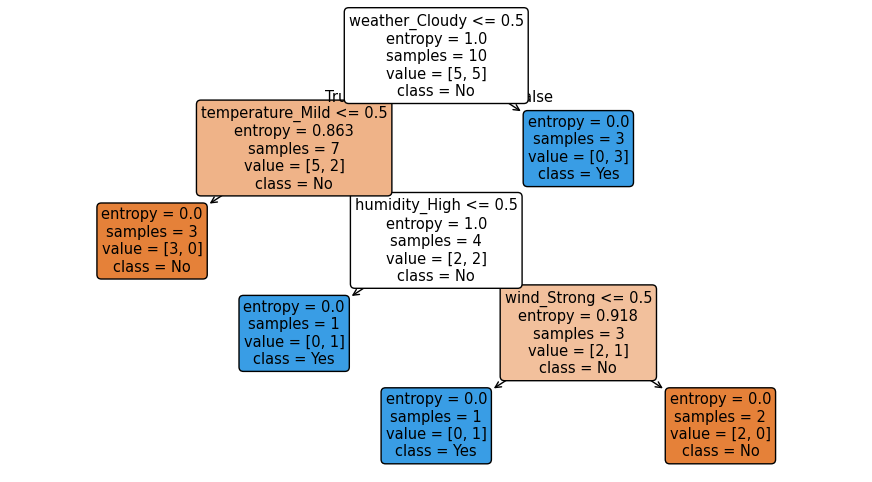

In [5]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(11, 6))
plot_tree(tree, feature_names=list(X.columns), class_names=list(tree.classes_), filled=True, rounded=True)
plt.show()

## 3. Đường đi của một mẫu từ gốc tới lá

`decision_path` cho biết mẫu đi qua những nút nào; dự đoán là nhãn đa số của nút lá cuối cùng.

In [6]:
sample = X.iloc[[2]]          # ngày 3: Sunny, Mild, Normal, Strong
node_ids = tree.decision_path(sample).indices
feature = tree.tree_.feature
threshold = tree.tree_.threshold
for node in node_ids:
    if feature[node] < 0:     # nút lá
        print('Nút %d là nút lá -> dự đoán: %s' % (node, tree.predict(sample)[0]))
    else:
        name = X.columns[feature[node]]
        value = sample.iloc[0, feature[node]]
        branch = '<=' if value <= threshold[node] else '>'
        print('Nút %d: %s = %d %s %.1f' % (node, name, value, branch, threshold[node]))

Nút 0: weather_Cloudy = 0 <= 0.5
Nút 1: temperature_Mild = 1 > 0.5
Nút 3: humidity_High = 0 <= 0.5
Nút 4 là nút lá -> dự đoán: Yes
